# Formula models and prediction

Follow a feature that shapes how this language is used in practice.

Work with a small fixture so that every returned value can be checked by hand. Keep the ordering of inputs visible. Trace resource ownership, data shape or scheduling as appropriate, and identify the exact point where the result becomes available to the caller.

The formula y ~ x includes an intercept. predict builds a design for new rows using the fitted terms. Coefficients and predictions answer different questions.

In [1]:
from pathlib import Path
import sys, math, statistics
import numpy as np
import matplotlib.pyplot as plt

here = Path.cwd()
sys.path.insert(0, str(here.parent.parent))
from course_runner import run_native

## Native source

`native.R`

```r
train <- data.frame(x = 0:4, y = c(2, 5, 8, 11, 14))
model <- lm(y ~ x, data = train)
test <- data.frame(x = c(-1, 0, 2, 5))
cat(as.numeric(predict(model, newdata = test)))
```

## Execute the native listing

The formula y ~ x includes an intercept. predict builds a design for new rows using the fitted terms. Coefficients and predictions answer different questions. Inspect the object with str() before transforming it. Type, names, dimensions and missingness can all affect how an expression is evaluated.

In [2]:
x = [-1, 0, 2, 5]
expected = np.asarray([3 * v + 2 for v in x], dtype=float)
engine, stdout = run_native(here / "native.R")
observed = np.asarray([float(v) for v in stdout.split()])
assert observed.shape == expected.shape
np.testing.assert_allclose(observed, expected, rtol=2e-7, atol=2e-7)
print("Runtime:", engine)
print("Native stdout:", stdout.strip())
print("Largest absolute difference:", f"{np.max(np.abs(observed-expected)):.3g}")

Runtime: R
Native stdout: -1 2 8 17
Largest absolute difference: 0


## Read the output

The independent calculation describes the expected output. Its agreement with the native result tests both the values and their order. The marks show the independent Python reference at each position.

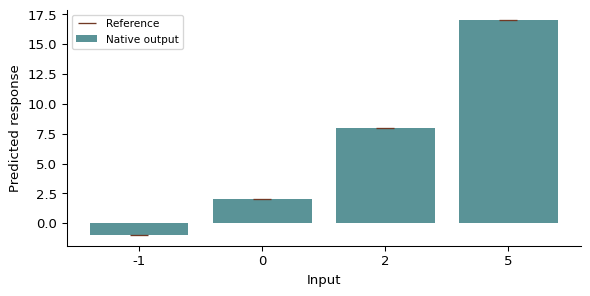

In [3]:
labels = [str(v) for v in x]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(6.1, 3), constrained_layout=True)
ax.bar(positions, observed, color="#367b80", alpha=0.82, label="Native output")
ax.plot(
    positions,
    expected,
    linestyle="none",
    marker="_",
    markersize=13,
    color="#713925",
    label="Reference",
)
ax.set(xticks=positions, xticklabels=labels, xlabel="Input", ylabel="Predicted response")
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

The independent calculation describes the expected output. Its agreement with the native result tests both the values and their order.

## Exercise

Change the input length, add a repeated value and predict all output positions before running the programme.

## References

[R Core Team, An Introduction to R](https://cran.r-project.org/doc/manuals/r-release/R-intro.html)